# NSL-KDD Data Investigation — toward Quantum Reservoir Computing for Anomaly Detection

**Goal of the overall project**
- Use **Reservoir Computing** — specifically **Quantum Reservoir Computing (QRC)** on a **photonic quantum computer** (Quandela, via the [Perceval](https://perceval.quandela.net/) library) — for **security management**.
- Tasks, in increasing difficulty:
  1. **Anomaly detection (binary):** is a connection *normal* or an *attack/anomaly*?
  2. **Attack categorisation (5-class):** `normal`, `DoS`, `Probe`, `R2L`, `U2R`.
  3. (Stretch) **Fine-grained attack identification:** the 23 raw labels.

**Goal of this notebook**
Understand the dataset well enough to design the QRC input encoding: which features matter,
how they are distributed, how imbalanced the classes are, and how to compress 41 features
into the *few* continuous parameters a small photonic reservoir can accept (phase-shifter
angles / photon input states on a handful of modes).

**Dataset:** `NSL_KDD_labeled.csv` — the NSL-KDD *KDDTrain+* set (125,973 connection records,
41 features + `label`). NSL-KDD is the de-duplicated, rebalanced successor of KDD Cup '99.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

# --- plotting defaults: quiet grid, no chart junk ---
mpl.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})

# Fixed category colors — assigned to entities, never cycled
CAT_COLORS = {
    "normal": "#4C78A8",   # blue
    "DoS":    "#E45756",   # red
    "Probe":  "#F58518",   # orange
    "R2L":    "#72B7B2",   # teal
    "U2R":    "#B279A2",   # purple
}
CAT_ORDER = ["normal", "DoS", "Probe", "R2L", "U2R"]

DATA_PATH = r"D:\Python\AI\Code\ReservoirComputing\NSL_KDD_labeled.csv"
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(125973, 42)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.00,0.00,0.00,150,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13,1,0.0,0.0,0.0,0.0,0.08,0.15,0.00,255,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,123,6,1.0,1.0,0.0,0.0,0.05,0.07,0.00,255,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune
3,0,tcp,http,SF,232,8153,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,5,0.2,0.2,0.0,0.0,1.00,0.00,0.00,30,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal
4,0,tcp,http,SF,199,420,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,30,32,0.0,0.0,0.0,0.0,1.00,0.00,0.09,255,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal


## 1. Structure, types, integrity

41 features + `label`. The 41 features fall into four well-known groups:

| Group | Columns | Meaning |
|---|---|---|
| **Basic** (1–9) | `duration` … `urgent` | properties of the single TCP/UDP/ICMP connection |
| **Content** (10–22) | `hot` … `is_guest_login` | payload-derived, needed for R2L/U2R (they hide *inside* one connection) |
| **Time-based traffic** (23–31) | `count` … `srv_diff_host_rate` | statistics over the **last 2 seconds** — this is the *temporal* signal a reservoir exploits |
| **Host-based traffic** (32–41) | `dst_host_*` | statistics over the last 100 connections to the same host |

In [2]:
print("Missing values :", df.isna().sum().sum())
print("Duplicate rows :", df.duplicated().sum())
print()
print(df.dtypes.value_counts())
df.describe().T[["mean", "std", "min", "50%", "max"]].round(3)

Missing values : 0
Duplicate rows : 0

int64      23
float64    15
object      4
Name: count, dtype: int64


,mean,std,min,50%,max
duration,287.145,2604.515,0.0,0.00,4.290800e+04
src_bytes,45566.743,5870331.182,0.0,44.00,1.379964e+09
dst_bytes,19779.114,4021269.151,0.0,0.00,1.309937e+09
land,0.000,0.014,0.0,0.00,1.000000e+00
wrong_fragment,0.023,0.254,0.0,0.00,3.000000e+00
urgent,0.000,0.014,0.0,0.00,3.000000e+00
hot,0.204,2.150,0.0,0.00,7.700000e+01
num_failed_logins,0.001,0.045,0.0,0.00,5.000000e+00
logged_in,0.396,0.489,0.0,0.00,1.000000e+00
num_compromised,0.279,23.942,0.0,0.00,7.479000e+03


**Findings**
- No missing values, no duplicate rows (NSL-KDD removed the KDD'99 redundancy — good, no leakage from duplicates).
- 3 categorical features: `protocol_type` (3), `service` (70), `flag` (11). The rest numeric.
- `num_outbound_cmds` is **constant 0** → drop it.
- Many content features are ~99% zero (`land`, `urgent`, `num_shells`, …) — sparse but *not* useless: they are precisely the rare fingerprints of R2L/U2R attacks.

In [3]:
num = df.select_dtypes(include=np.number)
constant = [c for c in num.columns if num[c].nunique() <= 1]
near_zero = {c: float((num[c] != 0).mean()) for c in num.columns
             if num[c].nunique() > 1 and (num[c] != 0).mean() < 0.01}
print("Constant columns          :", constant)
print("Columns <1% nonzero (share of nonzero rows):")
for c, r in sorted(near_zero.items(), key=lambda kv: kv[1]):
    print(f"   {c:<22s} {100*r:6.3f}%")

Constant columns          : ['num_outbound_cmds']
Columns <1% nonzero (share of nonzero rows):
   is_host_login           0.001%
   urgent                  0.007%
   land                    0.020%
   num_shells              0.037%
   su_attempted            0.064%
   num_failed_logins       0.097%
   root_shell              0.134%
   num_file_creations      0.228%
   num_access_files        0.295%
   num_root                0.515%
   wrong_fragment          0.865%
   is_guest_login          0.942%


## 2. Labels: from 23 raw labels to the targets we actually train on

We map raw labels → the standard 4 attack categories + normal. This gives us both targets:
- `y_binary` = normal vs attack (task 1)
- `y_cat` = 5 classes (task 2)

In [4]:
ATTACK_MAP = {
    "normal": "normal",
    # DoS — denial of service
    "neptune": "DoS", "back": "DoS", "land": "DoS", "pod": "DoS", "smurf": "DoS",
    "teardrop": "DoS", "apache2": "DoS", "udpstorm": "DoS", "processtable": "DoS", "mailbomb": "DoS",
    # Probe — surveillance / port scanning
    "satan": "Probe", "ipsweep": "Probe", "nmap": "Probe", "portsweep": "Probe",
    "mscan": "Probe", "saint": "Probe",
    # R2L — remote-to-local (unauthorized remote access)
    "guess_passwd": "R2L", "ftp_write": "R2L", "imap": "R2L", "phf": "R2L",
    "multihop": "R2L", "warezmaster": "R2L", "warezclient": "R2L", "spy": "R2L",
    "xlock": "R2L", "xsnoop": "R2L", "snmpguess": "R2L", "snmpgetattack": "R2L",
    "httptunnel": "R2L", "sendmail": "R2L", "named": "R2L",
    # U2R — user-to-root (privilege escalation)
    "buffer_overflow": "U2R", "loadmodule": "U2R", "rootkit": "U2R", "perl": "U2R",
    "sqlattack": "U2R", "xterm": "U2R", "ps": "U2R",
}
df["category"] = df["label"].map(ATTACK_MAP)
assert df["category"].notna().all(), "unmapped label found"
df["is_attack"] = (df["category"] != "normal").astype(int)

print(df["label"].value_counts())

label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2
Name: count, dtype: int64


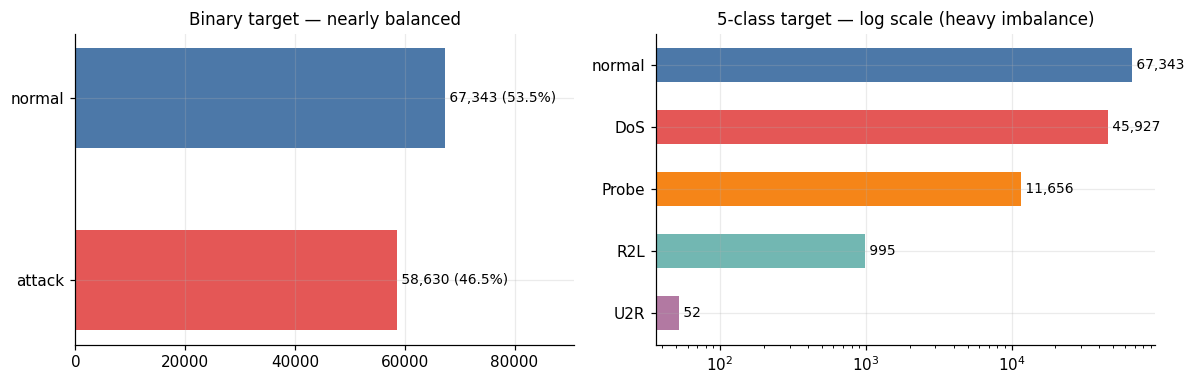

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

# left: binary balance
counts_bin = df["is_attack"].value_counts().rename({0: "normal", 1: "attack"})
axes[0].barh(counts_bin.index[::-1], counts_bin.values[::-1],
             color=["#E45756", "#4C78A8"], height=0.55)
for y, v in zip(counts_bin.index[::-1], counts_bin.values[::-1]):
    axes[0].text(v, y, f" {v:,} ({v/len(df):.1%})", va="center", fontsize=9)
axes[0].set_title("Binary target — nearly balanced")
axes[0].set_xlim(0, counts_bin.max() * 1.35)

# right: 5-class, log scale because of extreme imbalance
counts_cat = df["category"].value_counts().reindex(CAT_ORDER)
axes[1].barh(counts_cat.index[::-1], counts_cat.values[::-1],
             color=[CAT_COLORS[c] for c in counts_cat.index[::-1]], height=0.55)
for y, v in zip(counts_cat.index[::-1], counts_cat.values[::-1]):
    axes[1].text(v, y, f" {v:,}", va="center", fontsize=9)
axes[1].set_xscale("log")
axes[1].set_title("5-class target — log scale (heavy imbalance)")
plt.tight_layout()
plt.show()

**Findings**
- **Binary task is nearly balanced** (53.5% normal / 46.5% attack) → accuracy is a meaningful metric, no resampling needed. Great first QRC benchmark.
- **5-class task is brutally imbalanced**: DoS ≈ 46k, Probe ≈ 12k, but **R2L = 995** and **U2R = 52**. A tiny quantum reservoir will never learn U2R from 52 samples.
  - Plan: report per-class recall + macro-F1 (never plain accuracy), and consider merging R2L+U2R into one "intrusion" class or using class weights in the (classical) readout layer.
- 5 label values dominate everything: `normal`, `neptune`, `satan`, `ipsweep`, `portsweep` cover ~94% of rows.

## 3. Categorical features vs attacks

`service` and `flag` are extremely informative — a large part of the classical signal lives here.

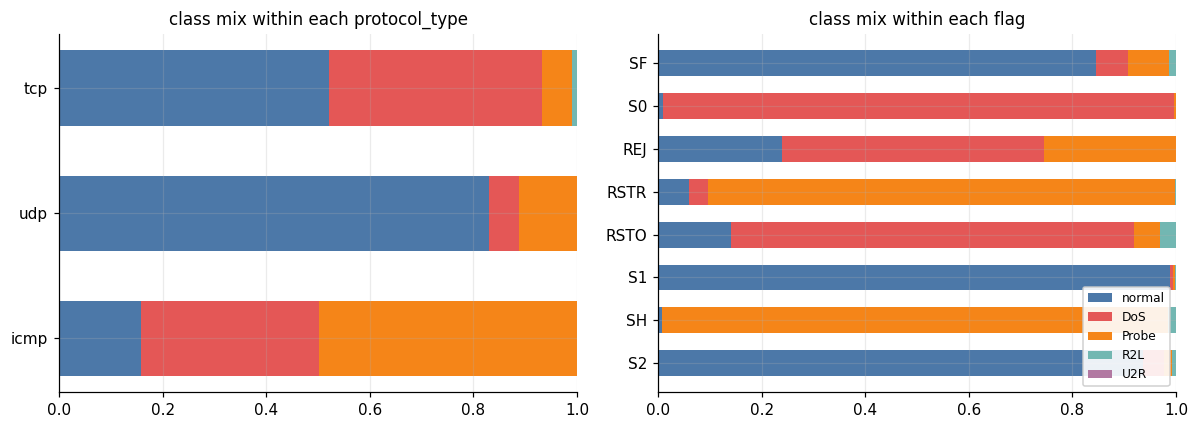

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, col in zip(axes, ["protocol_type", "flag"]):
    ct = pd.crosstab(df[col], df["category"]).reindex(columns=CAT_ORDER)
    ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False).index[:8]]
    share = ct.div(ct.sum(axis=1), axis=0)
    ypos = np.arange(len(share))[::-1]
    left = np.zeros(len(share))
    for cat in CAT_ORDER:
        ax.barh(ypos, share[cat].values, left=left, color=CAT_COLORS[cat],
                height=0.6, label=cat)
        left += share[cat].values
    ax.set_yticks(ypos)
    ax.set_yticklabels(share.index)
    ax.set_xlim(0, 1)
    ax.set_title(f"class mix within each {col}")
axes[1].legend(loc="lower right", fontsize=8, framealpha=0.9)
plt.tight_layout()
plt.show()

In [7]:
svc = (df.groupby("service")
         .agg(n=("label", "size"), attack_rate=("is_attack", "mean"))
         .sort_values("n", ascending=False))
print("Top-15 services by volume:")
svc.head(15).round(3)

Top-15 services by volume:


,n,attack_rate
service,,
http,40338,0.057
private,21853,0.955
domain_u,9043,0.001
smtp,7313,0.039
ftp_data,6860,0.273
eco_i,4586,0.892
other,4359,0.403
ecr_i,3077,0.938
telnet,2353,0.610


**Findings**
- `flag` alone almost solves DoS: `S0` (connection attempt, no reply — SYN flood signature) is ~99% attack; `SF` (normal completion) is mostly normal. `REJ`/`RSTR` skew Probe.
- `service`: `private`, `ecr_i` (ICMP echo-reply → smurf), `eco_i` (echo → sweeps) are >89% attack; `domain_u`, `smtp`, `http` are mostly normal.
- **Encoding decision for QRC:** with 70 service values, one-hot would explode the input dimension (~120 columns), which a small photonic circuit cannot take.
  Options, in order of preference for QRC:
  1. **Target/frequency encoding** (service → its attack rate / log frequency) → 1 continuous value per categorical, ideal for phase encoding;
  2. Group rare services into `other` then one-hot only the top ~10;
  3. Full one-hot + PCA (see §6).

## 4. Numeric features: distributions & the scaling problem

Photonic encodings (phase shifters) want inputs in a bounded range like $[0, \pi]$.
Raw NSL-KDD numerics span **9 orders of magnitude** — scaling strategy matters more than usual.

In [8]:
key = ["duration", "src_bytes", "dst_bytes", "count", "srv_count",
       "serror_rate", "same_srv_rate", "dst_host_srv_count", "logged_in"]
df[key].describe(percentiles=[.5, .95, .99]).T[["mean", "50%", "95%", "99%", "max"]]

,mean,50%,95%,99%,max
duration,287.144650,0.0,4.0,9590.56,4.290800e+04
src_bytes,45566.743000,44.0,1480.0,54540.00,1.379964e+09
dst_bytes,19779.114421,0.0,8314.0,25519.00,1.309937e+09
count,84.107555,14.0,286.0,511.00,5.110000e+02
srv_count,27.737888,8.0,158.0,492.00,5.110000e+02
serror_rate,0.284485,0.0,1.0,1.00,1.000000e+00
same_srv_rate,0.660928,1.0,1.0,1.00,1.000000e+00
dst_host_srv_count,115.653005,63.0,255.0,255.00,2.550000e+02
logged_in,0.395736,0.0,1.0,1.00,1.000000e+00


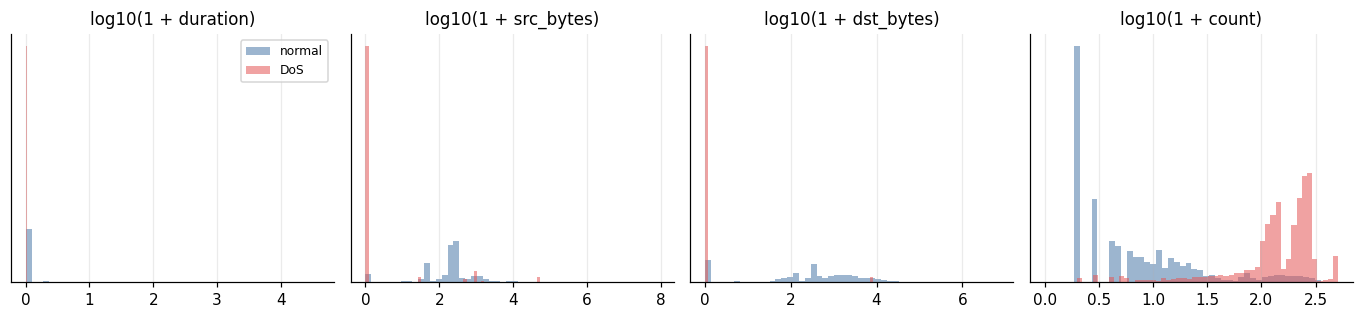

In [9]:
heavy = ["duration", "src_bytes", "dst_bytes", "count"]
fig, axes = plt.subplots(1, 4, figsize=(12.5, 3))
for ax, c in zip(axes, heavy):
    x = np.log10(df[c] + 1)
    for cat, colr in [("normal", CAT_COLORS["normal"]), ("DoS", CAT_COLORS["DoS"])]:
        ax.hist(x[df["category"] == cat], bins=50, alpha=0.55,
                color=colr, label=cat, density=True)
    ax.set_title(f"log10(1 + {c})")
    ax.set_yticks([])
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Findings**
- `src_bytes`/`dst_bytes` reach **1.3 GB** while the median is ~44 B / 0 B. `duration` is 0 for >75% of rows.
- Even in log space the normal-vs-DoS separation on these is visible (DoS: tiny/zero payloads at very high connection counts).
- The `*_rate` features (17 of them) are already in $[0,1]$ — **free lunch for photonic phase encoding**, no transform needed.
- **Scaling plan:** `log1p` → then `MinMax` (or `QuantileTransformer`) → map to $[0, \pi]$. Plain `StandardScaler` would be destroyed by the GB-scale outliers.

## 5. Which features separate the classes?

Point-biserial correlation with the binary target, plus a per-category view of the strongest ones.

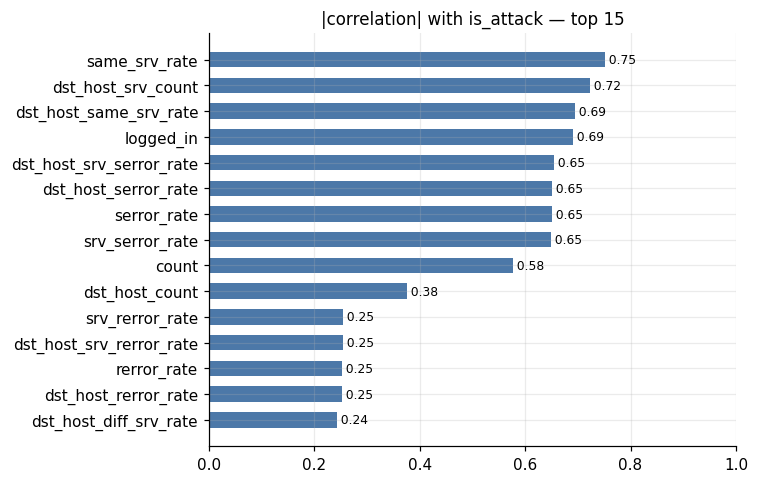

In [10]:
numc = df.select_dtypes(include=np.number).drop(columns=["is_attack"])
numc = numc.loc[:, numc.nunique() > 1]              # drop constant
corr = numc.apply(lambda s: s.corr(df["is_attack"])).abs().sort_values(ascending=False)

top = corr.head(15)[::-1]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top.index, top.values, color="#4C78A8", height=0.6)
for i, v in enumerate(top.values):
    ax.text(v, i, f" {v:.2f}", va="center", fontsize=8)
ax.set_title("|correlation| with is_attack — top 15")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()

In [11]:
top_feats = ["same_srv_rate", "dst_host_srv_count", "logged_in", "serror_rate",
             "count", "dst_host_same_srv_rate"]
df.groupby("category")[top_feats].mean().reindex(CAT_ORDER).round(3)

,same_srv_rate,dst_host_srv_count,logged_in,serror_rate,count,dst_host_same_srv_rate
category,,,,,,
normal,0.969,190.286,0.711,0.013,22.518,0.812
DoS,0.192,26.524,0.021,0.748,178.090,0.123
Probe,0.697,42.367,0.007,0.047,77.052,0.391
R2L,0.997,42.440,0.914,0.012,1.297,0.727
U2R,0.932,9.885,0.885,0.038,5.808,0.781


**Findings**
- Strongest binary signals: `same_srv_rate`, `dst_host_srv_count`, `logged_in`, and the SYN-error family (`serror_rate`, `srv_serror_rate`, `dst_host_serror_rate` — all ≈0.65, and heavily redundant with each other).
- Per-category profiles are distinctive:
  - **DoS**: `serror_rate` ≈ 0.88, huge `count`, `logged_in` ≈ 0 → floods of failed half-open connections.
  - **Probe**: low `same_srv_rate` (0.24) → touching many *different* services, the scanning fingerprint.
  - **R2L/U2R**: look almost like **normal** on traffic features (`logged_in` ≈ 1, low counts) — they only differ on *content* features (`hot`, `num_failed_logins`, `num_file_creations`, `root_shell`). This is why every classifier struggles on them, and why we must keep the sparse content features despite their 99% zeros.
- Feature redundancy is high (the serror family, the srv-count family). PCA/feature selection will compress well — good news for a small reservoir.

## 6. Dimensionality compression — how many modes does the reservoir need?

A realistic Perceval photonic reservoir has ~6–12 modes, i.e. **we can inject only a handful
of continuous parameters per sample**. Question: how much variance / class information
survives an aggressive linear compression?

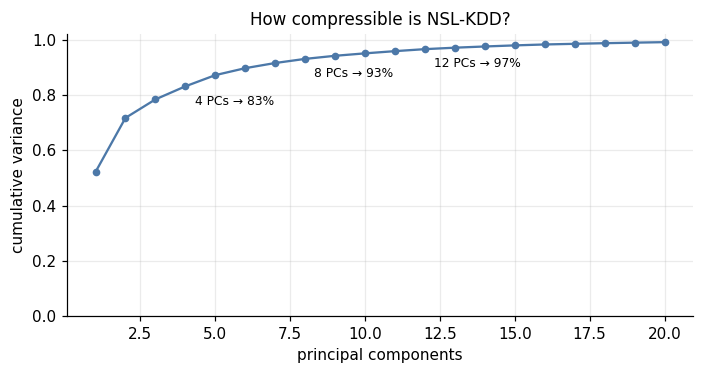

In [12]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA

# Preprocess exactly as planned for QRC: target-encode categoricals, log1p heavy numerics, minmax
work = df.copy()
for c in ["protocol_type", "service", "flag"]:
    rate = work.groupby(c)["is_attack"].mean()
    work[c + "_te"] = work[c].map(rate)

feat_cols = [c for c in numc.columns] + ["protocol_type_te", "service_te", "flag_te"]
X = work[feat_cols].copy()
for c in ["duration", "src_bytes", "dst_bytes", "count", "srv_count",
          "dst_host_count", "dst_host_srv_count", "hot", "num_compromised", "num_root"]:
    X[c] = np.log1p(X[c])
X = MinMaxScaler().fit_transform(X)

pca = PCA().fit(X)
cum = np.cumsum(pca.explained_variance_ratio_)
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(range(1, 21), cum[:20], marker="o", ms=4, color="#4C78A8")
for k in [4, 8, 12]:
    ax.annotate(f"{k} PCs → {cum[k-1]:.0%}", (k, cum[k-1]),
                textcoords="offset points", xytext=(6, -12), fontsize=8)
ax.set_xlabel("principal components"); ax.set_ylabel("cumulative variance")
ax.set_ylim(0, 1.02); ax.set_title("How compressible is NSL-KDD?")
plt.tight_layout(); plt.show()

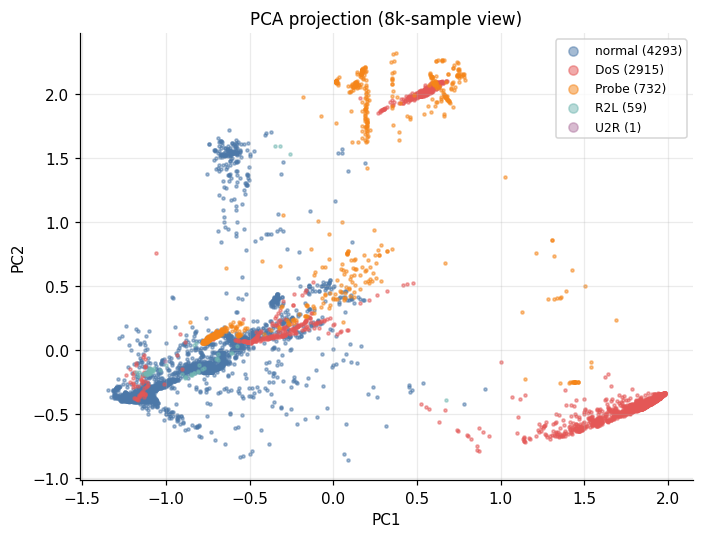

In [13]:
# Visual check: do 2 PCs already separate the categories?
Z = PCA(n_components=2).fit_transform(X)
rng = np.random.default_rng(0)
idx = rng.choice(len(Z), 8000, replace=False)  # subsample for readability

fig, ax = plt.subplots(figsize=(6.5, 5))
for cat in CAT_ORDER:
    m = (df["category"].values[idx] == cat)
    ax.scatter(Z[idx][m, 0], Z[idx][m, 1], s=4, alpha=0.5,
               color=CAT_COLORS[cat], label=f"{cat} ({m.sum()})")
ax.legend(markerscale=3, fontsize=8)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title("PCA projection (8k-sample view)")
plt.tight_layout(); plt.show()

**Findings (fill in exact numbers after running)**
- A small number of PCs captures most variance — an **8–12 dimensional input is a defensible compression**, matching an 8–12 mode photonic circuit.
- In the 2-PC view, normal / DoS / Probe form largely separable clouds; R2L/U2R sit inside the normal cloud (consistent with §5).
- **QRC encoding candidates** (to benchmark later):
  1. `PCA(k)` → scale to $[0,\pi]$ → phase-shifter angles on $k$ modes;
  2. Top-$k$ features by mutual information instead of PCA (more interpretable);
  3. For the *temporal* reservoir variant: feed connections as a time-ordered stream so the reservoir's fading memory sees the same 2-second context that `count`/`serror_rate` summarize by hand.

## 7. A classical baseline — the number QRC has to beat

Before any quantum hardware: a linear model and a small tree ensemble on the compressed input.
The QRC pipeline is *encoding → fixed random reservoir → linear readout*, so the fair
comparison is **linear readout on raw compressed features** (what does the reservoir add?).

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score

Xp = PCA(n_components=8).fit_transform(X)          # the same 8-dim input a QRC would get
y_bin = df["is_attack"].values
y_cat = df["category"].values

Xtr, Xte, ytr, yte, ctr, cte = train_test_split(
    Xp, y_bin, y_cat, test_size=0.25, stratify=y_cat, random_state=42)

logit = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
rf    = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42).fit(Xtr, ytr)
print("=== Binary, 8-dim PCA input ===")
print(f"linear readout  F1 = {f1_score(yte, logit.predict(Xte)):.4f}")
print(f"random forest   F1 = {f1_score(yte, rf.predict(Xte)):.4f}")

logit5 = LogisticRegression(max_iter=1000, class_weight="balanced").fit(Xtr, ctr)
print("\n=== 5-class, linear readout, class-weighted ===")
print(classification_report(cte, logit5.predict(Xte), digits=3))

=== Binary, 8-dim PCA input ===
linear readout  F1 = 0.9649
random forest   F1 = 0.9954



=== 5-class, linear readout, class-weighted ===
              precision    recall  f1-score   support

         DoS      0.989     0.965     0.977     11482
       Probe      0.847     0.970     0.905      2914
         R2L      0.153     0.779     0.255       249
         U2R      0.010     0.769     0.020        13
      normal      0.980     0.856     0.914     16836

    accuracy                          0.906     31494
   macro avg      0.596     0.868     0.614     31494
weighted avg      0.964     0.906     0.930     31494



**Interpretation**
- The **linear-readout binary F1** is the floor: a QRC whose reservoir features beat this shows genuine nonlinear benefit from the quantum reservoir.
- The RF score approximates the ceiling reachable with this 8-dim input.
- Expect the 5-class report to show good DoS/Probe recall and poor R2L/U2R — that gap is exactly where a richer (quantum) feature map could earn its keep, and what we should track per class.

⚠️ **Caveat:** this split is within KDDTrain+. The official **KDDTest+** contains attack types never seen in training — real generalisation must eventually be measured there.

## 8. Summary & decisions for the QRC pipeline

| # | Decision | Reason |
|---|---|---|
| 1 | Drop `num_outbound_cmds` | constant zero |
| 2 | Keep sparse content features | only signal for R2L/U2R |
| 3 | Target-encode `service`/`flag`/`protocol_type` | 1 value each vs ~120 one-hot columns |
| 4 | `log1p` on byte/count features, then MinMax → $[0, \pi]$ | 9 orders of magnitude; phase encoding needs bounded input |
| 5 | Compress to **8–12 dims** (PCA or MI top-k) | matches feasible photonic mode count |
| 6 | Start with **binary** task | balanced, clean benchmark |
| 7 | 5-class: macro-F1 + per-class recall, class weights in readout | U2R has 52 samples |
| 8 | Record the §7 linear baseline | it's the number the reservoir must beat |
| 9 | Get **KDDTest+** for the final eval | unseen attack types = true anomaly-detection test |

**Next notebook (`02_qrc_pipeline.ipynb`):**
1. `pip install perceval-quandela` (import as `import perceval as pcvl` — note: another
   package named `perceval` may shadow it; use a clean env).
2. Build an $m$-mode random interferometer (`pcvl.Unitary` / `GenericInterferometer`),
   encode each 8-dim sample into input phase shifters, inject a Fock state, and use the
   output photon-counting distribution as the reservoir feature vector.
3. Train a ridge/logistic **readout** on those features; compare to §7 baselines.
4. Swap the local simulator for the **Quandela Cloud** backend (`pcvl.RemoteProcessor`)
   for real-hardware runs.